# Stress-Testing Experiments Evaluation

**Model :: CrossEfficientNet**

In this notebook we conduct targeted stress-testings experiments using the knowledge abstractions we create over augmented images. These stress-tests include:

- Over-all Performance
- Performance over Data Distributions (Native Benchmarks)
- Performance over Augmentation size
- Performance over Semantic Change (LANCE): cos-dist between caption embeddings
- Performance over entity groups (subject distributions)

In [246]:
import os
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_fscore_support, accuracy_score
import matplotlib.pyplot as plt
from tqdm import tqdm
import json
# import ipdb

import warnings
warnings.filterwarnings('ignore')

In [247]:
!pip install seaborn

### Data Paths & Data Loading

In [248]:
model = "DIRE"

# CSV files with model predictions:
INPAINT_EVAL = "DIRE/preds/inpainting.csv"
LANCE_EVAL = "DIRE/preds/lance.csv"

pred_files = [INPAINT_EVAL, LANCE_EVAL]

# extended metadata paths for all augmentations 
INPAINT_META = "Diffm_FakeImage_Dataset_5k/inference_meta.csv"

#### Creating directory in which all computations will be saved

In [249]:
if not os.path.exists(model):
    os.mkdir(model)

### Data Loading (Predictions & Metadata)

In [250]:
def get_data_type(x):
    """
    Determines type from `model` column.
    """
    if x.model in ['RePaint', 'StableDiffusion']:
        return 'inpainting'
    elif x.model in ['lance']:
        return 'prompt-to-prompt'
    else:
        return 'real'


def load_model_predictions(pred_files, metadata=None):
    """
    Loads model predictions from a list of CSV files 
    and ensures all relevant metadata is present.
    
    Input:
        `pred_files` (list): list of CSV file paths with model predictions
        `metadata` (path): file path with image metadata. If not provided,
            the code assumes this information is already present in the
            prediction files.
    Output:
        `pred_df` (pd.DF): pandas DataFrame with model predictions and
            relevant metadata. 
    """
    
    pred_df = pd.concat([pd.read_csv(f) for f in pred_files])
    datasets = list(pred_df.dataset.unique())
    
    # standardizing dataset names if necessary:
    if 'ade20k' in datasets:
        pred_df['dataset'] = pred_df['dataset'].str.replace('ade20k', 'ADE20K')
        pred_df['dataset'] = pred_df['dataset'].str.replace('ade', 'ADE20K')
        pred_df['dataset'] = pred_df['dataset'].str.replace('helen', 'Helen')
        pred_df['dataset'] = pred_df['dataset'].str.replace('hpd', 'HumanParsing')
        pred_df['dataset'] = pred_df['dataset'].str.replace('celeba', 'CelebA-HQ')
        pred_df['dataset'] = pred_df['dataset'].str.replace('city', 'CityScapes')
        
    # checking for metadata information:
    if ('SA_change_category' not in pred_df.columns) \
    and ('semantic_change_category' not in pred_df.columns) \
    and metadata is not None:
        meta = pd.read_csv(metadata)['id', 'dataset', 'SA_change_category', 'semantic_change_category', 'pertrubation_type']
        pred_df = pred_df.merge(meta, how='left', on='id')
        
    elif ('SA_change_category' not in pred_df.columns) \
    and ('semantic_change_category' not in pred_df.columns):
        raise ValueError('Metadata information not detected in predictions file, but no metadata file provided. Please provide a path for `metadata`.')
        
    # adding `type` column, which is will be (inpainting, prompt-to-prompt, real)
    pred_df['type'] = pred_df.apply(get_data_type, axis=1)
        
    return pred_df



## Helper Functions

### Metric Computations

In [251]:
def compute_metrics(data_sample, model, group=None, fake_img_count=None, real_img_count=None):
    """
    This function will compute all relevant metrics for 
    a group of predictions. This includes the following:
    
        accuracy, precision, recall, f1, 
        precision-1, recall-1, f1-1,
        precision-0, recall-0, f1-0
        
    Metrics are returns in a pd.DataFrame.
    """
    
    if 'pred_binary' not in data_sample.columns:
        binary_preds = [1 if p >=0.5 else 0 for p in data_sample.pred]
        data_sample['pred_binary'] = binary_preds

    if 'label_binary' not in data_sample.columns:
        binary_labels = [1 if l == 'fake' else 0 for l in data_sample.label]
        data_sample['label_binary'] = binary_labels

    y_true = list(data_sample.label_binary)
    y_pred = list(data_sample.pred_binary)

    accuracy = accuracy_score(y_true, y_pred)
    precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(y_true, y_pred, beta=1.0, average='macro')
    precision, recall, f1, support = precision_recall_fscore_support(y_true, y_pred, beta=1.0)

    metrics_df = pd.DataFrame()
    metrics_df['model'] = [model]
    if group:
        metrics_df['group'] = [group]
    if fake_img_count is not None:
        metrics_df['fake_imgs'] = [fake_img_count]
    if real_img_count is not None:
        metrics_df['real_imgs'] = [real_img_count]
    metrics_df['accuracy'] = [accuracy]
    metrics_df['precision'] = [precision_macro]
    metrics_df['recall'] = [recall_macro]
    metrics_df['f1'] = [f1_macro]
    metrics_df['precision_real'] = [precision[0]]
    metrics_df['precision_fake'] = [precision[1]]
    metrics_df['recall_real'] = [recall[0]]
    metrics_df['recall_fake'] = [recall[1]]
    metrics_df['f1_real'] = [f1[0]]
    metrics_df['f1_fake'] = [f1[1]]

    return metrics_df


def compute_fake_metrics(data_sample, model, group=None, fake_img_count=None):
    """
    This function will compute only positive class (fake) metrics for 
    a group of predictions. This includes the following:
    
        accuracy, precision-1, recall-1, f1-1,
        
    Metrics are returns in a pd.DataFrame.
    """
    
    if 'pred_binary' not in data_sample.columns:
        binary_preds = [1 if p >=0.5 else 0 for p in data_sample.pred]
        data_sample['pred_binary'] = binary_preds

    if 'label_binary' not in data_sample.columns:
        binary_labels = [1 if l == 'fake' else 0 for l in data_sample.label]
        data_sample['label_binary'] = binary_labels

    y_true = list(data_sample.label_binary)
    y_pred = list(data_sample.pred_binary)
    
    accuracy = accuracy_score(y_true, y_pred)
    precision, recall, f1, support = precision_recall_fscore_support(y_true, y_pred, beta=1.0)

    metrics_df = pd.DataFrame()
    metrics_df['model'] = [model]
    if group:
        metrics_df['group'] = [group]
    if fake_img_count is not None:
        metrics_df['fake_imgs'] = [fake_img_count]
        
    # we do not show precision because it will always be 1:
    metrics_df['accuracy'] = [accuracy]
    metrics_df['recall_fake'] = [recall[1]]
    metrics_df['f1_fake'] = [f1[1]]

    return metrics_df


def save_metrics(metrics, root_dir, fname):
    """
    Saves metrics as a CSV file at the given
    root directory and the provided file name.
    """
    path = os.path.join(root_dir, fname)
    metrics.to_csv(path, index=False)
    print(f"Metrics saved at ::  {path}")



### Matplotlib Visualizations

In [252]:
def plot_all_metrics(metrics, group_names):
    """
    Plots all model performance metrics. This includes:
    Precision-1, Recall-1, Precision-0, Recall-0 
    
    """
    model = str(metrics.model.iloc[0])
    model_metrics = {}
    for i, grp in enumerate(group_names):
        mm = list(metrics.loc[metrics.group==grp][['precision_fake', 'recall_fake', 'precision_real', 'recall_real']].iloc[0])
        model_metrics[grp] = mm
    metric_names = ['Precision-1', 'Recall-1', 'Precision-0', 'Recall-0']
    
    index = range(len(metric_names))
    colors = plt.cm.Set2.colors
    plt.grid(True, linestyle='--', color='gray', linewidth=0.5)

    for i, grp in enumerate(model_metrics.keys()):
        bar_width = 0.8 / len(group_names)
        if i > 0:
            index = [j+bar_width for j in index]
        bars = plt.bar(index, model_metrics[grp], width=bar_width, label=grp, color=colors[i])
                
        # Add text labels on top of each bar
        for bar in bars:
            height = bar.get_height()
            plt.text(bar.get_x() + bar.get_width() / 2, height, round(height, 2), ha='center', va='bottom')


    plt.xlabel('Metrics', fontweight="bold")
    plt.ylabel('Performance  (0 - 1)', fontweight="bold")
    plt.title(f'{model} Performance Comparison', fontweight="bold")
    
    tick_offset = -(bar_width/2)*(len(group_names)-1)
    plt.xticks([i + tick_offset for i in index], metric_names)  # Adjusting ticks position

    plt.legend()
    plt.tight_layout()  
    plt.show()
    
    
def plot_fake_metrics(metrics, group_names):
    """
    Plots fake-class specific metrics. This includes:
    Precision-1, Recall-1
    
    """
    model = str(metrics.model.iloc[0])
    model_metrics = {}
    for i, grp in enumerate(group_names):
        mm = list(metrics.loc[metrics.group==grp][['precision_fake', 'recall_fake']].iloc[0])
        model_metrics[grp] = mm
    metric_names = ['Precision-1', 'Recall-1']
    
    index = range(len(metric_names))
    colors = plt.cm.Set2.colors
    plt.grid(True, linestyle='--', color='gray', linewidth=0.5)

    for i, grp in enumerate(model_metrics.keys()):
        bar_width = 0.8 / len(group_names)
        if i > 0:
            index = [j+bar_width for j in index]
        bars = plt.bar(index, model_metrics[grp], width=bar_width, label=grp, color=colors[i])
        
        # Add text labels on top of each bar
        for bar in bars:
            height = bar.get_height()
            plt.text(bar.get_x() + bar.get_width() / 2, height, round(height, 2), ha='center', va='bottom')

    plt.xlabel('Metrics', fontweight="bold")
    plt.ylabel('Performance  (0 - 1)', fontweight="bold")
    plt.title(f'{model} Performance Comparison', fontweight="bold")
    
    tick_offset = -(bar_width/2)*(len(group_names)-1)
    plt.xticks([i + tick_offset for i in index], metric_names)  # Adjusting ticks position

    plt.legend()
    plt.tight_layout()  
    plt.show()
    
    

### Seaborn Visualizations

In [253]:
import seaborn as sns
sns.set_theme(style="whitegrid")


def pivot_predictions(preds, fake_only=False):
    """
    Pivots the prediction DataFrame into a long format
    that will be easy to use with Seaborn plotting. 
    
    Currently only considers Precision & Recall metrics,
    will only retain metrics on the positive / "fake"
    class if `fake_only` == True.
    """
    preds = preds.rename(
        columns={'precision_real': 'Precision-0', 
                  'precision_fake': 'Precision-1',
                  'recall_real': 'Recall-0',
                  'recall_fake': 'Recall-1'
    })
    
    metrics = [m for m in preds.columns if 'Precision-' in m or 'Recall-' in m]
    if fake_only:
        metrics = [m for m in metrics if '1' in m]
        
    long_data = []
    for i, row in preds.iterrows():
        for m in metrics:
            d_ = {}
            d_['model'] = row.model
            d_['group'] = row.group
            d_['metric'] = m
            d_['value'] = row[m]
            long_data.append(d_)
          
    long_preds = pd.DataFrame(long_data)
    return long_preds


def plot_metrics_sns(preds, fake_only=False, title=None, save=True):
    """
    This function creates a seaborn bar plot demonstarting
    the performance metrics of a model on various "groups"
    of data.
    
    It will only visualize Precision & Recall metrics,
    will only retain metrics on the positive / "fake"
    class if `fake_only` == True.
    
    If `save` == True, the plots will save in a directory named
    after the model and named by the title of the plot.
    """
    long_preds = pivot_predictions(preds, fake_only=fake_only)
    model = preds.iloc[0].model
    sns.set_palette("Paired")

    g = sns.catplot(
        data=long_preds, kind="bar",
        x="metric", y="value", hue="group",
        errorbar="sd", alpha=.8, height=6
    )
    g.despine(left=True)
    g.legend.set_title("")
    
    for ax in g.axes.ravel():
        for c in ax.containers:
            ax.bar_label(c, fmt='%.2f')
            
    plt.xlabel("Metrics", fontsize=14, fontweight='bold');
    plt.ylabel("Performance Score (0 - 1)", fontsize=14, fontweight='bold');
    plt.tick_params(axis='both', which='major', labelsize=12)
    
    if title:
        plt.title(title, fontsize=16, fontweight='bold')
    else:
        plt.title(f"{model} Performance Metrics", fontsize=16, fontweight='bold')
        
    if save:
        fn = title.lower().replace("\n", " ").replace(" ", "_") + ".png"
        save_path = os.path.join(model, fn)
        plt.savefig(save_path, bbox_inches='tight')
        
    plt.show()



## General Performance

In [254]:
preds = load_model_predictions(pred_files, metadata=INPAINT_META)
preds.head()

,Unnamed: 0,dataset,image_path,id,name,pertrubation_type,change_value,model,SA_change_category,label,split,pred,type
0,2453,ADE20K,ADE20K_People_256/images/ADE_train_00020216.jpg,ADE_train_00020216,NaN,NaN,NaN,NaN,NaN,real,test,0.0,real
1,2454,ADE20K,ADE20K_People_256/images/ADE_train_00002130.jpg,ADE_train_00002130,NaN,NaN,NaN,NaN,NaN,real,train,0.0,real
2,2455,ADE20K,ADE20K_People_256/images/ADE_frame_00000294.jpg,ADE_frame_00000294,NaN,NaN,NaN,NaN,NaN,real,train,0.0,real
3,2456,ADE20K,ADE20K_People_256/images/ADE_train_00019313.jpg,ADE_train_00019313,NaN,NaN,NaN,NaN,NaN,real,val,0.0,real
4,2457,ADE20K,ADE20K_People_256/images/ADE_train_00024579.jpg,ADE_train_00024579,NaN,NaN,NaN,NaN,NaN,real,val,0.0,real


### Inpainting

In [255]:
data_inpaint = preds.loc[(preds.type=='inpainting') | (preds.type=='real')]
metrics_df_inpaint = compute_metrics(data_inpaint, model, group='inpainting', fake_img_count=None, real_img_count=None)
metrics_df_inpaint

,model,group,accuracy,precision,recall,f1,precision_real,precision_fake,recall_real,recall_fake,f1_real,f1_fake
0,DIRE,inpainting,0.598661,0.483118,0.496471,0.413733,0.612155,0.354081,0.944989,0.047952,0.743001,0.084466


### Lance

In [256]:
data_lance = preds.loc[(preds.type=='prompt-to-prompt') | (preds.type=='real')]
metrics_df_lance = compute_metrics(data_lance, model, group='prompt-to-prompt')
metrics_df_lance

,model,group,accuracy,precision,recall,f1,precision_real,precision_fake,recall_real,recall_fake,f1_real,f1_fake
0,DIRE,prompt-to-prompt,0.854648,0.552961,0.531606,0.535723,0.897289,0.208633,0.944989,0.118223,0.920521,0.150924


### Visualization

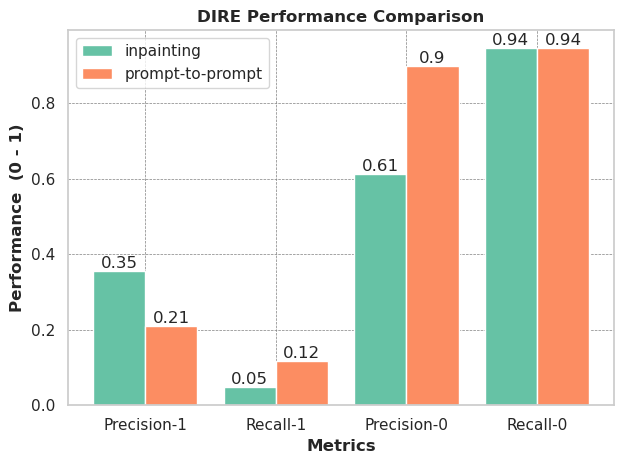

In [257]:
# combined metrics:
all_metrics_general = pd.concat([metrics_df_inpaint, metrics_df_lance])
plot_all_metrics(all_metrics_general, list(all_metrics_general.group))

In [258]:
all_metrics_general.keys()

Index(['model', 'group', 'accuracy', 'precision', 'recall', 'f1',
       'precision_real', 'precision_fake', 'recall_real', 'recall_fake',
       'f1_real', 'f1_fake'],
      dtype='object')

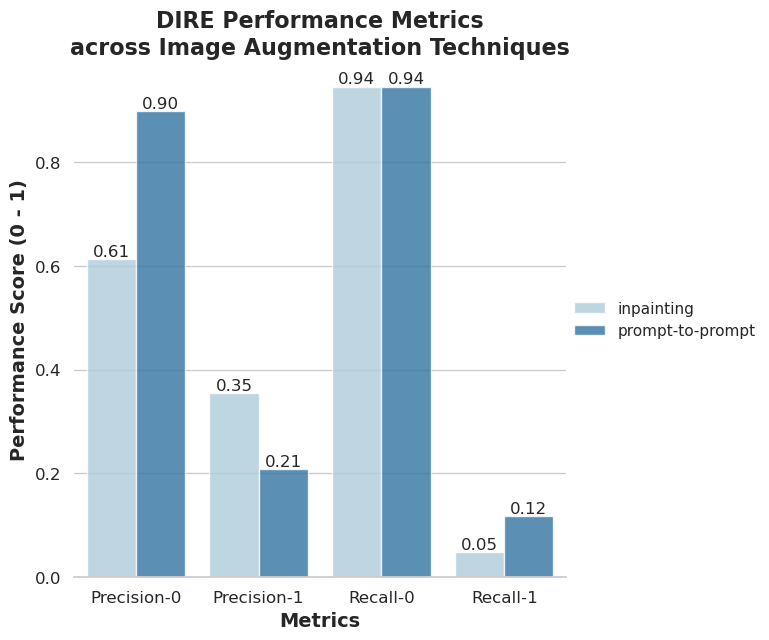

In [259]:
title = f"{model} Performance Metrics\nacross Image Augmentation Techniques"
plot_metrics_sns(all_metrics_general, fake_only=False, title=title)

## Performance across Benchmarks | Inpaint

In [260]:
groups = list(data_inpaint.dataset.unique())
groups

['ADE20K', 'CityScapes', 'CelebA-HQ', 'HumanParsing']

### Inpainting | ADE20K

In [261]:
inpaint_ade20k = data_inpaint.loc[data_inpaint.dataset==groups[0]]
fake_img_count = len(inpaint_ade20k.loc[inpaint_ade20k.label=='fake'])
real_img_count = len(inpaint_ade20k.loc[inpaint_ade20k.label=='real'])

metrics_df_ade20k = compute_metrics(inpaint_ade20k, model, group=groups[0], fake_img_count=fake_img_count, real_img_count=real_img_count)
metrics_df_ade20k


,model,group,fake_imgs,real_imgs,accuracy,precision,recall,f1,precision_real,precision_fake,recall_real,recall_fake,f1_real,f1_fake
0,DIRE,ADE20K,2044,3744,0.646856,0.323428,0.5,0.392782,0.646856,0.0,1.0,0.0,0.785564,0.0


### Inpainting | CityScapes

In [262]:
inpaint_cityscapes = data_inpaint.loc[data_inpaint.dataset==groups[1]]
fake_img_count = len(inpaint_cityscapes.loc[inpaint_cityscapes.label=='fake'])
real_img_count = len(inpaint_cityscapes.loc[inpaint_cityscapes.label=='real'])

metrics_df_cs = compute_metrics(inpaint_cityscapes, model, group=groups[1], fake_img_count=fake_img_count, real_img_count=real_img_count)
metrics_df_cs

,model,group,fake_imgs,real_imgs,accuracy,precision,recall,f1,precision_real,precision_fake,recall_real,recall_fake,f1_real,f1_fake
0,DIRE,CityScapes,694,1188,0.359192,0.404091,0.44509,0.329507,0.469799,0.338384,0.117845,0.772334,0.188425,0.470588


### Inpainting | CelebA-HQ

In [263]:
inpaint_celeba = data_inpaint.loc[data_inpaint.dataset==groups[2]]
fake_img_count = len(inpaint_celeba.loc[inpaint_celeba.label=='fake'])
real_img_count = len(inpaint_celeba.loc[inpaint_celeba.label!='fake'])

metrics_df_celeba = compute_metrics(inpaint_celeba, model, group=groups[2], fake_img_count=fake_img_count, real_img_count=real_img_count)
metrics_df_celeba


### Inpainting | HumanParsing

In [ ]:
inpaint_hp = data_inpaint.loc[data_inpaint.dataset==groups[3]]
fake_img_count = len(inpaint_hp.loc[inpaint_hp.label=='fake'])
real_img_count = len(inpaint_hp.loc[inpaint_hp.label!='fake'])

metrics_df_hp = compute_metrics(inpaint_hp, model, group=groups[3], fake_img_count=fake_img_count, real_img_count=real_img_count)
metrics_df_hp


,model,group,fake_imgs,real_imgs,accuracy,precision,recall,f1,precision_real,precision_fake,recall_real,recall_fake,f1_real,f1_fake
0,CNNSpot,HumanParsing,5648,7532,0.574203,0.786519,0.503187,0.370621,0.573037,1.0,1.0,0.006374,0.728574,0.012667


### Visualization

In [ ]:
all_metrics_inpaint = pd.concat([metrics_df_ade20k, metrics_df_cs, metrics_df_celeba, metrics_df_hp])
save_metrics(all_metrics_inpaint, model, "inpainting_dataset_metrics.csv")

all_metrics_inpaint


Metrics saved at ::  CNNSpot/inpainting_dataset_metrics.csv


,model,group,fake_imgs,real_imgs,accuracy,precision,recall,f1,precision_real,precision_fake,recall_real,recall_fake,f1_real,f1_fake
0,CNNSpot,ADE20K,2044,3744,0.646856,0.323428,0.500000,0.392782,0.646856,0.0,1.0,0.000000,0.785564,0.000000
0,CNNSpot,CityScapes,694,1188,0.631243,0.315622,0.500000,0.386971,0.631243,0.0,1.0,0.000000,0.773941,0.000000
0,CNNSpot,CelebA-HQ,4189,7532,0.643205,0.821496,0.500836,0.393022,0.642991,1.0,1.0,0.001671,0.782708,0.003337
0,CNNSpot,HumanParsing,5648,7532,0.574203,0.786519,0.503187,0.370621,0.573037,1.0,1.0,0.006374,0.728574,0.012667


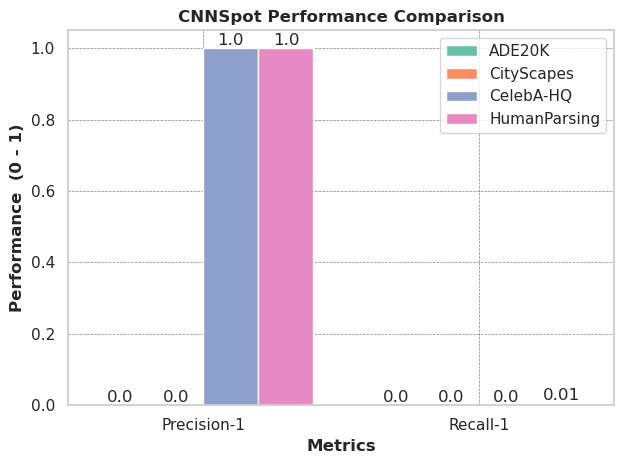

In [ ]:
plot_fake_metrics(all_metrics_inpaint, list(all_metrics_inpaint.group))

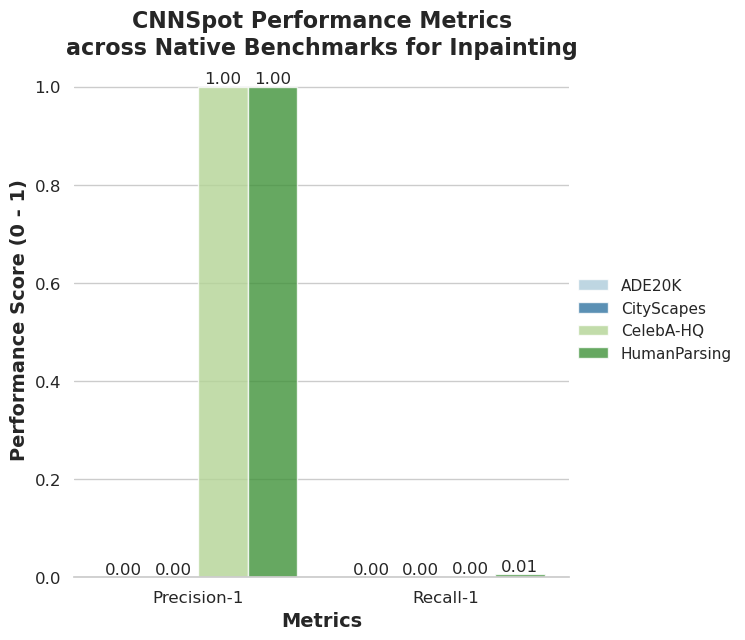

In [ ]:
title = f"{model} Performance Metrics\nacross Native Benchmarks for Inpainting"
plot_metrics_sns(all_metrics_inpaint, fake_only=True, title=title)

## Performance across Benchmarks | LANCE

In [ ]:
groups = list(data_lance.dataset.unique())
groups

['ADE20K', 'CityScapes', 'CelebA-HQ', 'HumanParsing', 'Helen']

### Lance | ADE20K

In [ ]:
lance_ade20k = data_lance.loc[data_lance.dataset==groups[0]]
fake_img_count = len(lance_ade20k.loc[lance_ade20k.label=='fake'])
real_img_count = len(lance_ade20k.loc[lance_ade20k.label=='real'])

metrics_df_ade20k = compute_metrics(lance_ade20k, model, group=groups[0], fake_img_count=fake_img_count, real_img_count=real_img_count)
metrics_df_ade20k


,model,group,fake_imgs,real_imgs,accuracy,precision,recall,f1,precision_real,precision_fake,recall_real,recall_fake,f1_real,f1_fake
0,CNNSpot,ADE20K,661,3744,0.85017,0.925068,0.500756,0.46101,0.850136,1.0,1.0,0.001513,0.918999,0.003021


### Lance | CityScapes

In [ ]:
lance_cityscapes = data_lance.loc[data_lance.dataset==groups[1]]
fake_img_count = len(lance_cityscapes.loc[lance_cityscapes.label=='fake'])
real_img_count = len(lance_cityscapes.loc[lance_cityscapes.label=='real'])

metrics_df_cs = compute_metrics(lance_cityscapes, model, group=groups[1], fake_img_count=fake_img_count, real_img_count=real_img_count)
metrics_df_cs


,model,group,fake_imgs,real_imgs,accuracy,precision,recall,f1,precision_real,precision_fake,recall_real,recall_fake,f1_real,f1_fake
0,CNNSpot,CityScapes,345,1188,0.774951,0.387476,0.5,0.436604,0.774951,0.0,1.0,0.0,0.873208,0.0


### Lance | CelebA-HQ

In [ ]:
lance_celeba = data_lance.loc[data_lance.dataset==groups[2]]
fake_img_count = len(lance_celeba.loc[lance_celeba.label=='fake'])
real_img_count = len(lance_celeba.loc[lance_celeba.label=='real'])

metrics_df_celeba = compute_metrics(lance_celeba, model, group=groups[2], fake_img_count=fake_img_count, real_img_count=real_img_count)
metrics_df_celeba


,model,group,fake_imgs,real_imgs,accuracy,precision,recall,f1,precision_real,precision_fake,recall_real,recall_fake,f1_real,f1_fake
0,CNNSpot,CelebA-HQ,219,7532,0.97252,0.986249,0.513699,0.519695,0.972498,1.0,1.0,0.027397,0.986057,0.053333


### Lance | HumanParsing

In [ ]:
lance_hp = data_lance.loc[data_lance.dataset==groups[3]]
fake_img_count = len(lance_hp.loc[lance_hp.label=='fake'])
real_img_count = len(lance_hp.loc[lance_hp.label=='real'])

metrics_df_hp = compute_metrics(lance_hp, model, group=groups[3], fake_img_count=fake_img_count, real_img_count=real_img_count)
metrics_df_hp


,model,group,fake_imgs,real_imgs,accuracy,precision,recall,f1,precision_real,precision_fake,recall_real,recall_fake,f1_real,f1_fake
0,CNNSpot,HumanParsing,241,7532,0.968995,0.484498,0.5,0.492127,0.968995,0.0,1.0,0.0,0.984254,0.0


### Lance | Helen

In [ ]:
lance_hp = data_lance.loc[data_lance.dataset==groups[4]]
fake_img_count = len(lance_hp.loc[lance_hp.label=='fake'])
real_img_count = len(lance_hp.loc[lance_hp.label=='real'])

metrics_df_helen = compute_metrics(lance_hp, model, group=groups[4], fake_img_count=fake_img_count, real_img_count=real_img_count)
metrics_df_helen


,model,group,fake_imgs,real_imgs,accuracy,precision,recall,f1,precision_real,precision_fake,recall_real,recall_fake,f1_real,f1_fake
0,CNNSpot,Helen,987,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### Visualization

In [ ]:
all_metrics_lance = pd.concat([metrics_df_ade20k, metrics_df_cs, metrics_df_celeba, metrics_df_hp, metrics_df_helen])
save_metrics(all_metrics_lance, model, "p2p_dataset_metrics.csv")

all_metrics_lance


Metrics saved at ::  CNNSpot/p2p_dataset_metrics.csv


,model,group,fake_imgs,real_imgs,accuracy,precision,recall,f1,precision_real,precision_fake,recall_real,recall_fake,f1_real,f1_fake
0,CNNSpot,ADE20K,661,3744,0.850170,0.925068,0.500756,0.461010,0.850136,1.0,1.0,0.001513,0.918999,0.003021
0,CNNSpot,CityScapes,345,1188,0.774951,0.387476,0.500000,0.436604,0.774951,0.0,1.0,0.000000,0.873208,0.000000
0,CNNSpot,CelebA-HQ,219,7532,0.972520,0.986249,0.513699,0.519695,0.972498,1.0,1.0,0.027397,0.986057,0.053333
0,CNNSpot,HumanParsing,241,7532,0.968995,0.484498,0.500000,0.492127,0.968995,0.0,1.0,0.000000,0.984254,0.000000
0,CNNSpot,Helen,987,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.000000


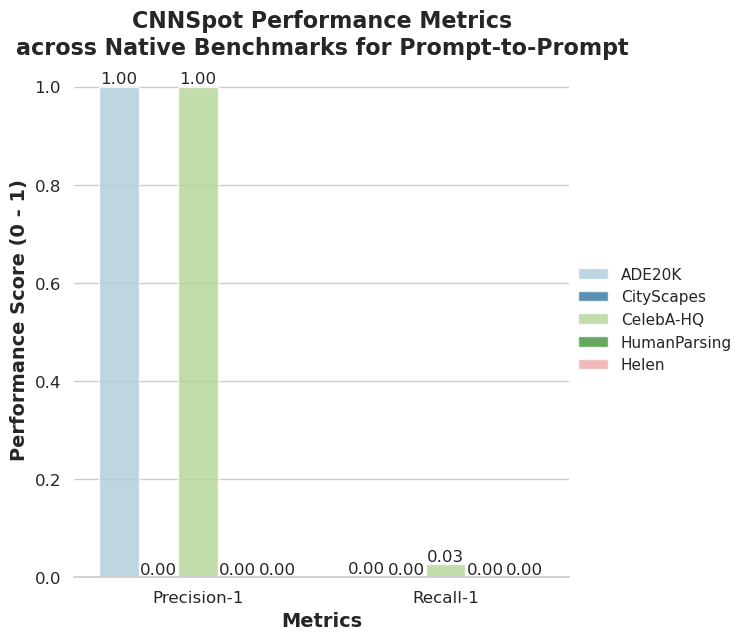

In [ ]:
title = f"{model} Performance Metrics\nacross Native Benchmarks for Prompt-to-Prompt"
plot_metrics_sns(all_metrics_lance, fake_only=True, title=title)


## Performance across SA bins | Inpaint

This surveys the fluctuation in model performance across area of augmentation

### Small | Bin = 1

In [ ]:
inpaint_1 = preds.loc[preds.SA_change_category==1.0]
fake_img_count = len(inpaint_1.loc[inpaint_1.label=='fake'])
real_img_count = len(inpaint_1.loc[inpaint_1.label=='real'])

metrics_df_1 = compute_fake_metrics(inpaint_1, model, group='bin: 1', fake_img_count=fake_img_count)
metrics_df_1

,model,group,fake_imgs,accuracy,recall_fake,f1_fake
0,CNNSpot,bin: 1,2921,0.002739,0.002739,0.005463


### Small_Medium | Bin = 2

In [ ]:
inpaint_2 = preds.loc[preds.SA_change_category==2.0]
fake_img_count = len(inpaint_2.loc[inpaint_2.label=='fake'])
real_img_count = len(inpaint_2.loc[inpaint_2.label=='real'])

metrics_df_2 = compute_fake_metrics(inpaint_2, model, group='bin: 2', fake_img_count=fake_img_count)
metrics_df_2

,model,group,fake_imgs,accuracy,recall_fake,f1_fake
0,CNNSpot,bin: 2,5354,0.003736,0.003736,0.007443


### Medium | Bin = 3

In [ ]:
inpaint_3 = preds.loc[preds.SA_change_category==3.0]
fake_img_count = len(inpaint_3.loc[inpaint_3.label=='fake'])
real_img_count = len(inpaint_3.loc[inpaint_3.label=='real'])

metrics_df_3 = compute_fake_metrics(inpaint_3, model, group='bin: 3', fake_img_count=fake_img_count)
metrics_df_3

,model,group,fake_imgs,accuracy,recall_fake,f1_fake
0,CNNSpot,bin: 3,2955,0.004399,0.004399,0.00876


### Medium-Large | Bin = 4

In [ ]:
inpaint_4 = preds.loc[preds.SA_change_category==4.0]
fake_img_count = len(inpaint_4.loc[inpaint_4.label=='fake'])
real_img_count = len(inpaint_4.loc[inpaint_4.label=='real'])

metrics_df_4 = compute_fake_metrics(inpaint_4, model, group='bin: 4', fake_img_count=fake_img_count)
metrics_df_4

,model,group,fake_imgs,accuracy,recall_fake,f1_fake
0,CNNSpot,bin: 4,2040,0.003431,0.003431,0.006839


### Large | Bin = 5

In [ ]:
inpaint_5 = preds.loc[preds.SA_change_category==5.0]
fake_img_count = len(inpaint_5.loc[inpaint_5.label=='fake'])
real_img_count = len(inpaint_5.loc[inpaint_5.label=='real'])

metrics_df_5 = compute_fake_metrics(inpaint_5, model, group='bin: 5', fake_img_count=fake_img_count)
metrics_df_5

,model,group,fake_imgs,accuracy,recall_fake,f1_fake
0,CNNSpot,bin: 5,1758,0.001138,0.001138,0.002273


### Visualization

#### Bar

In [ ]:
sa_bin_metrics = pd.concat([metrics_df_1, metrics_df_2, metrics_df_3, metrics_df_4, metrics_df_5])
save_metrics(sa_bin_metrics, model, "inpainting_surface_area_metrics.csv")

sa_bin_metrics


Metrics saved at ::  CNNSpot/inpainting_surface_area_metrics.csv


,model,group,fake_imgs,accuracy,recall_fake,f1_fake
0,CNNSpot,bin: 1,2921,0.002739,0.002739,0.005463
0,CNNSpot,bin: 2,5354,0.003736,0.003736,0.007443
0,CNNSpot,bin: 3,2955,0.004399,0.004399,0.008760
0,CNNSpot,bin: 4,2040,0.003431,0.003431,0.006839
0,CNNSpot,bin: 5,1758,0.001138,0.001138,0.002273


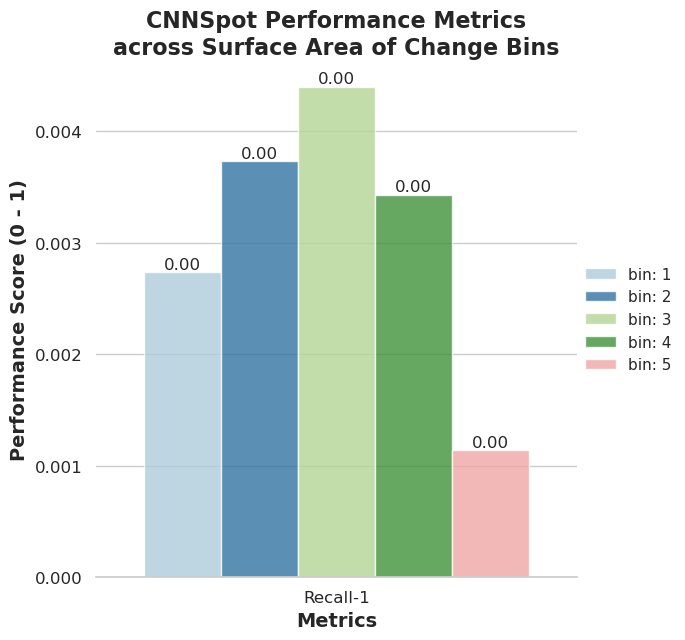

In [ ]:
title = f"{model} Performance Metrics\nacross Surface Area of Change Bins"
plot_metrics_sns(sa_bin_metrics, fake_only=True, title=title)

In [ ]:
preds.keys()

Index(['Unnamed: 0', 'dataset', 'image_path', 'id', 'name',
       'pertrubation_type', 'change_value', 'model', 'SA_change_category',
       'label', 'split', 'pred', 'type'],
      dtype='object')

#### Heatmaps

In [ ]:
# ## OLD CODE - DONT USE

# import matplotlib.pyplot as plt
# import numpy as np


# # join all performance metrics:
# all_metrics = pd.concat([metrics_df_1, metrics_df_2, metrics_df_3, metrics_df_4, metrics_df_5])
# all_metrics = all_metrics.sort_values(by=['group'])
# # all_metrics['precision_fake'] = all_metrics.precision_fake.apply(lambda x: round(x, 2))
# all_metrics['recall_fake'] = all_metrics.recall_fake.apply(lambda x: round(x, 2))


# # Sample precision and recall scores for four different models
# models = list(all_metrics.group)
# precision = list(all_metrics.precision_fake)
# recall = list(all_metrics.recall_fake)

# # Create a 2D array for precision and recall scores
# scores = np.array([precision, recall])

# # Create the heatmap
# plt.figure(figsize=(8, 6))
# plt.imshow(scores, cmap='viridis', interpolation='nearest', vmin=0.0, vmax=1.0)

# # Add color bar
# plt.colorbar(label='Score')

# # Set the tick labels
# plt.xticks(np.arange(len(models)), models)
# plt.yticks(np.arange(2), ['Precision-Fake', 'Recall-Fake'])

# # Add text annotations
# for i in range(len(models)):
#     for j in range(2):
#         plt.text(i, j, str(scores[j, i]), ha='center', va='center', color='white')

# # Set axis labels and title
# plt.xlabel('Surface Area Change Categories (Small --> Large)')
# plt.ylabel('Metrics')
# plt.title('Precision-1 and Recall-1 Scores for CrossEfficientNet')

# # Show plot
# plt.tight_layout()
# plt.show()

## Performance across Semantic Change bins | Lance

This surveys the fluctuation in model performance across area of augmentation

### Small | Bin = 1

In [ ]:
lance_1 = preds.loc[preds.SA_change_category==1.0]
fake_img_count = len(lance_1.loc[lance_1.label=='fake'])
real_img_count = len(lance_1.loc[lance_1.label=='real'])

metrics_df_1 = compute_fake_metrics(lance_1, model, group='bin: 1', fake_img_count=fake_img_count)
metrics_df_1

,model,group,fake_imgs,accuracy,recall_fake,f1_fake
0,CNNSpot,bin: 1,2921,0.002739,0.002739,0.005463


### Small_Medium | Bin = 2

In [ ]:
lance_2 = preds.loc[preds.SA_change_category==2.0]
fake_img_count = len(lance_2.loc[lance_2.label=='fake'])
real_img_count = len(lance_2.loc[lance_2.label=='real'])

metrics_df_2 = compute_fake_metrics(lance_2, model, group='bin: 2', fake_img_count=fake_img_count)
metrics_df_2

,model,group,fake_imgs,accuracy,recall_fake,f1_fake
0,CNNSpot,bin: 2,5354,0.003736,0.003736,0.007443


### Medium | Bin = 3

In [ ]:
lance_3 = preds.loc[preds.SA_change_category==3.0]
fake_img_count = len(lance_3.loc[lance_3.label=='fake'])
real_img_count = len(lance_3.loc[lance_3.label=='real'])

metrics_df_3 = compute_fake_metrics(lance_3, model, group='bin: 3', fake_img_count=fake_img_count)
metrics_df_3

,model,group,fake_imgs,accuracy,recall_fake,f1_fake
0,CNNSpot,bin: 3,2955,0.004399,0.004399,0.00876


### Medium-Large | Bin = 4

In [ ]:
lance_4 = preds.loc[preds.SA_change_category==4.0]
fake_img_count = len(lance_4.loc[lance_4.label=='fake'])
real_img_count = len(lance_4.loc[lance_4.label=='real'])

metrics_df_4 = compute_fake_metrics(lance_4, model, group='bin: 4', fake_img_count=fake_img_count)
metrics_df_4

,model,group,fake_imgs,accuracy,recall_fake,f1_fake
0,CNNSpot,bin: 4,2040,0.003431,0.003431,0.006839


### Large | Bin = 5

In [ ]:
lance_5 = preds.loc[preds.SA_change_category==5.0]
fake_img_count = len(lance_5.loc[lance_5.label=='fake'])
real_img_count = len(lance_5.loc[lance_5.label=='real'])

metrics_df_5 = compute_fake_metrics(lance_5, model, group='bin: 5', fake_img_count=fake_img_count)
metrics_df_5

,model,group,fake_imgs,accuracy,recall_fake,f1_fake
0,CNNSpot,bin: 5,1758,0.001138,0.001138,0.002273


### Visualization

In [ ]:
semantic_bin_metrics = pd.concat([metrics_df_1, metrics_df_2, metrics_df_3, metrics_df_4, metrics_df_5])
save_metrics(semantic_bin_metrics, model, "p2p_semantic_change_metrics.csv")

semantic_bin_metrics

Metrics saved at ::  CNNSpot/p2p_semantic_change_metrics.csv


,model,group,fake_imgs,accuracy,recall_fake,f1_fake
0,CNNSpot,bin: 1,2921,0.002739,0.002739,0.005463
0,CNNSpot,bin: 2,5354,0.003736,0.003736,0.007443
0,CNNSpot,bin: 3,2955,0.004399,0.004399,0.008760
0,CNNSpot,bin: 4,2040,0.003431,0.003431,0.006839
0,CNNSpot,bin: 5,1758,0.001138,0.001138,0.002273


#### Bar

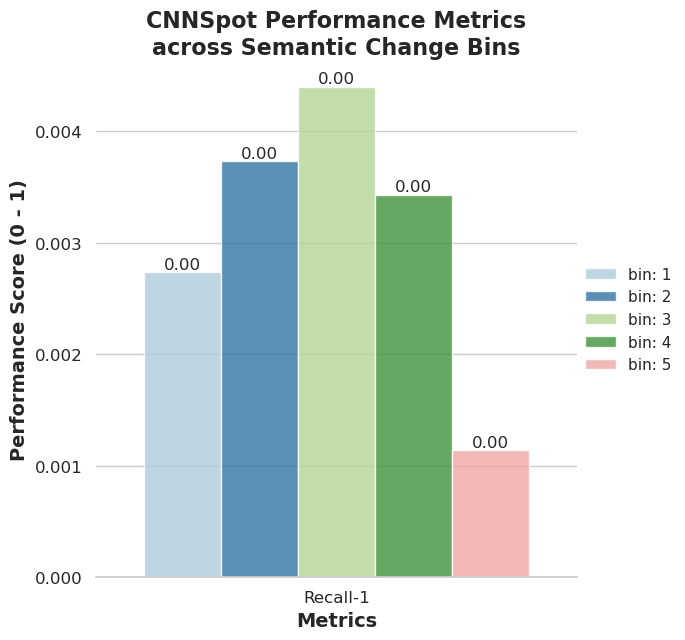

In [ ]:
title = f"{model} Performance Metrics\nacross Semantic Change Bins"
plot_metrics_sns(semantic_bin_metrics, fake_only=True, title=title)

#### Heatmaps

In [ ]:
# ## OLD CODE - DONT USE

# import matplotlib.pyplot as plt
# import numpy as np


# # join all performance metrics:
# all_metrics = pd.concat([metrics_df_1, metrics_df_2, metrics_df_3, metrics_df_4, metrics_df_5])
# all_metrics = all_metrics.sort_values(by=['group'])
# all_metrics['precision_fake'] = all_metrics.precision_fake.apply(lambda x: round(x, 2))
# all_metrics['recall_fake'] = all_metrics.recall_fake.apply(lambda x: round(x, 2))


# # Sample precision and recall scores for four different models
# models = list(all_metrics.group)
# precision = list(all_metrics.precision_fake)
# recall = list(all_metrics.recall_fake)

# # Create a 2D array for precision and recall scores
# scores = np.array([precision, recall])

# # Create the heatmap
# plt.figure(figsize=(8, 6))
# plt.imshow(scores, cmap='viridis', interpolation='nearest', vmin=0.0, vmax=1.0)

# # Add color bar
# plt.colorbar(label='Score')

# # Set the tick labels
# plt.xticks(np.arange(len(models)), models)
# plt.yticks(np.arange(2), ['Precision-Fake', 'Recall-Fake'])

# # Add text annotations
# for i in range(len(models)):
#     for j in range(2):
#         plt.text(i, j, str(scores[j, i]), ha='center', va='center', color='white')

# # Set axis labels and title
# plt.xlabel('Semantic Change Categories (Small --> Large)')
# plt.ylabel('Metrics')
# plt.title('Precision-1 and Recall-1 Scores for CrossEfficientNet')

# # Show plot
# plt.tight_layout()
# plt.show()

AttributeError: 'DataFrame' object has no attribute 'precision_fake'

## Performance across Augmentation Type | Lance

This surveys the fluctuation in model performance across types of augmentations conducted with prompt-to-prompt techniques:

In [ ]:
preds.pertrubation_type.unique()

array([nan, 'adjective', 'background', 'object', 'subject', 'weather'],
      dtype=object)

### Adjective

In [ ]:
group = 'adjective'
group_df = preds.loc[preds.pertrubation_type==group]
fake_img_count = len(group_df.loc[group_df.label=='fake'])
real_img_count = len(group_df.loc[group_df.label=='real'])

metrics_df_adj = compute_fake_metrics(group_df, model, group=group, fake_img_count=fake_img_count)
metrics_df_adj

,model,group,fake_imgs,accuracy,recall_fake,f1_fake
0,CNNSpot,adjective,518,0.001931,0.001931,0.003854


### Object

In [ ]:
group = 'object'
group_df = preds.loc[preds.pertrubation_type==group]
fake_img_count = len(group_df.loc[group_df.label=='fake'])
real_img_count = len(group_df.loc[group_df.label=='real'])

metrics_df_obj = compute_fake_metrics(group_df, model, group=group, fake_img_count=fake_img_count)
metrics_df_obj

,model,group,fake_imgs,accuracy,recall_fake,f1_fake
0,CNNSpot,object,718,0.002786,0.002786,0.005556


### Subject

In [ ]:
group = 'subject'
group_df = preds.loc[preds.pertrubation_type==group]
fake_img_count = len(group_df.loc[group_df.label=='fake'])
real_img_count = len(group_df.loc[group_df.label=='real'])

metrics_df_sub = compute_fake_metrics(group_df, model, group=group, fake_img_count=fake_img_count)
metrics_df_sub

,model,group,fake_imgs,accuracy,recall_fake,f1_fake
0,CNNSpot,subject,1050,0.00381,0.00381,0.00759


### Weather

In [ ]:
group = 'weather'
group_df = preds.loc[preds.pertrubation_type==group]
fake_img_count = len(group_df.loc[group_df.label=='fake'])
real_img_count = len(group_df.loc[group_df.label=='real'])

metrics_df_w = compute_fake_metrics(group_df, model, group=group, fake_img_count=fake_img_count)
metrics_df_w

,model,group,fake_imgs,accuracy,recall_fake,f1_fake
0,CNNSpot,weather,38,0.0,0.0,0.0


### Background

In [ ]:
group = 'background'
group_df = preds.loc[preds.pertrubation_type==group]
fake_img_count = len(group_df.loc[group_df.label=='fake'])
real_img_count = len(group_df.loc[group_df.label=='real'])

metrics_df_back = compute_fake_metrics(group_df, model, group=group, fake_img_count=fake_img_count)
metrics_df_back

,model,group,fake_imgs,accuracy,recall_fake,f1_fake
0,CNNSpot,background,129,0.0,0.0,0.0


### Visualization

In [ ]:
pert_type_metrics = pd.concat([metrics_df_adj, metrics_df_obj, metrics_df_sub, metrics_df_w, metrics_df_back])
save_metrics(pert_type_metrics, model, "p2p_perturb_type_metrics.csv")

pert_type_metrics


Metrics saved at ::  CNNSpot/p2p_perturb_type_metrics.csv


,model,group,fake_imgs,accuracy,recall_fake,f1_fake
0,CNNSpot,adjective,518,0.001931,0.001931,0.003854
0,CNNSpot,object,718,0.002786,0.002786,0.005556
0,CNNSpot,subject,1050,0.003810,0.003810,0.007590
0,CNNSpot,weather,38,0.000000,0.000000,0.000000
0,CNNSpot,background,129,0.000000,0.000000,0.000000


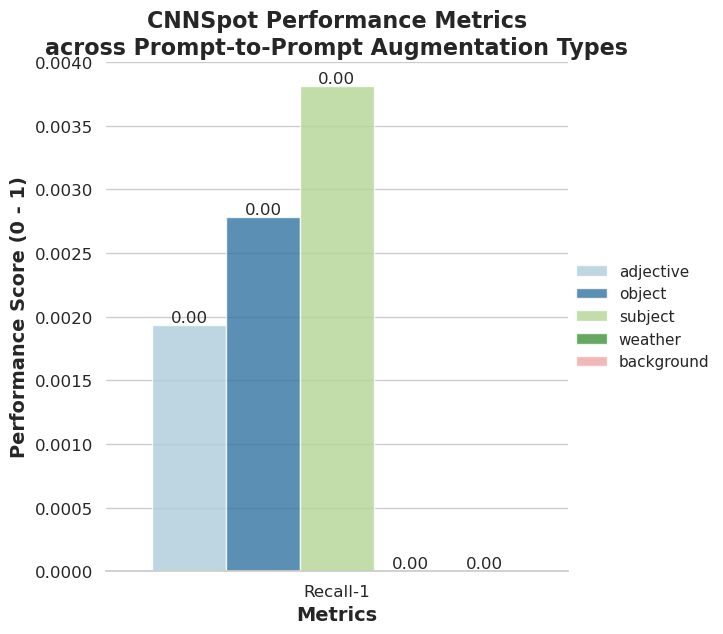

In [ ]:
title = f"{model} Performance Metrics\nacross Prompt-to-Prompt Augmentation Types"
plot_metrics_sns(pert_type_metrics, fake_only=True, title=title)